In [1]:
# ================================================================
# TAHAP 1 : IMPORT LIBRARY
# Tujuan  : Memuat library yang dibutuhkan program.
# ================================================================

import os                          # Mengambil ekstensi nama file
import io                          # Membaca file dari memori (bytes)
import math                        # Memeriksa bobot (math.isfinite)
import numpy as np                 # Operasi angka dan nilai NaN
import pandas as pd                # Pengolahan tabel data
import matplotlib.pyplot as plt    # Membuat grafik

from IPython.display import display  # Menampilkan tabel rapi di Colab
from google.colab import files       # Upload/download file di Colab

In [2]:
# ================================================================
# TAHAP 2 : FUNGSI BANTU DAN TEMPLATE DATA
# Tujuan  : Fungsi kecil yang dipakai di banyak tahap lain,
#           serta pembuat template contoh data.
# ================================================================

def garis():
    """Menampilkan garis pembatas."""
    print("=" * 75)


def tampilkan_judul(judul):
    """Menampilkan judul bagian program di layar."""
    print()
    garis()
    print(judul)
    garis()


def format_angka(nilai, digit=4):
    """
    Mengubah angka menjadi teks dengan jumlah desimal tertentu.
    Jika nilainya kosong (NaN), ditampilkan sebagai "NaN".
    """
    if pd.isna(nilai):
        return "NaN"

    return f"{nilai:.{digit}f}"


def buat_template_data():
    """
    Membuat file template Excel sebagai contoh format input,
    lalu mengunduhnya ke komputer pengguna.
    """

    # Data contoh: 5 alternatif dengan 4 kriteria
    template = pd.DataFrame({
        "Alternatif": [
            "Alternatif 1",
            "Alternatif 2",
            "Alternatif 3",
            "Alternatif 4",
            "Alternatif 5"
        ],
        "C1": [80, 75, 90, 70, 85],
        "C2": [5000000, 4500000, 6000000, 4000000, 5500000],
        "C3": [4, 5, 3, 4, 5],
        "C4": [85, 80, 95, 75, 90]
    })

    nama_file = "template_data_smart.xlsx"
    template.to_excel(nama_file, index=False)

    print(f"Template berhasil dibuat: {nama_file}")
    files.download(nama_file)

# --- JALANKAN: (opsional) unduh template contoh data ---
pilihan_template = input(
    "\nUnduh template contoh data terlebih dahulu? [y/n]: "
).strip().lower()

if pilihan_template in ["y", "ya", "yes"]:
    buat_template_data()


Unduh template contoh data terlebih dahulu? [y/n]: n


In [3]:
# ================================================================
# TAHAP 3 : UPLOAD DAN MEMBACA DATA
# Tujuan  : Pengguna mengunggah file CSV/Excel, lalu isinya
#           dibaca menjadi tabel (DataFrame) dan dibersihkan.
# ================================================================

def baca_file_data():
    """
    Mengunggah dan membaca file CSV atau Excel.

    Return:
        dataframe   : data yang berhasil dibaca
        nama_file   : nama file yang diunggah
    """

    tampilkan_judul("UPLOAD DATA ALTERNATIF")

    print("Silakan unggah file CSV atau Excel.")
    print("Format yang didukung: .csv, .xlsx, dan .xls")
    print()

    # --- 3.a. Membuka dialog upload di Colab ---
    # Hasilnya dictionary {nama_file: isi_file_dalam_bytes}
    uploaded = files.upload()

    if len(uploaded) == 0:
        raise ValueError("Tidak ada file yang diunggah.")

    # Menggunakan file pertama jika pengguna mengunggah beberapa file
    nama_file = list(uploaded.keys())[0]
    isi_file = uploaded[nama_file]

    ekstensi = os.path.splitext(nama_file)[1].lower()

    # --- 3.b. Membaca file sesuai jenisnya ---
    try:
        if ekstensi == ".csv":

            # Pemisah (koma/titik koma/tab) dideteksi otomatis
            try:
                dataframe = pd.read_csv(
                    io.BytesIO(isi_file),
                    sep=None,
                    engine="python"
                )

            except UnicodeDecodeError:
                # Alternatif encoding jika UTF-8 gagal
                dataframe = pd.read_csv(
                    io.BytesIO(isi_file),
                    sep=None,
                    engine="python",
                    encoding="latin-1"
                )

        elif ekstensi in [".xlsx", ".xls"]:

            file_excel = pd.ExcelFile(io.BytesIO(isi_file))

            print("\nDaftar sheet yang tersedia:")
            for nomor, nama_sheet in enumerate(file_excel.sheet_names, start=1):
                print(f"{nomor}. {nama_sheet}")

            # Jika hanya ada satu sheet, langsung dipakai
            if len(file_excel.sheet_names) == 1:
                sheet_dipilih = file_excel.sheet_names[0]
                print(f"\nSheet yang digunakan: {sheet_dipilih}")

            # Jika ada banyak sheet, pengguna diminta memilih
            else:
                while True:
                    pilihan_sheet = input(
                        "\nMasukkan nomor sheet yang akan digunakan: "
                    ).strip()

                    if pilihan_sheet.isdigit():
                        nomor_sheet = int(pilihan_sheet)

                        if 1 <= nomor_sheet <= len(file_excel.sheet_names):
                            sheet_dipilih = file_excel.sheet_names[
                                nomor_sheet - 1
                            ]
                            break

                    print("Nomor sheet tidak valid.")

            dataframe = pd.read_excel(
                io.BytesIO(isi_file),
                sheet_name=sheet_dipilih
            )

        else:
            raise ValueError(
                "Format file tidak didukung. "
                "Gunakan file CSV, XLSX, atau XLS."
            )

    except Exception as error:
        raise ValueError(
            f"File tidak dapat dibaca. Detail kesalahan: {error}"
        )

    # --- 3.c. Membersihkan tabel ---

    # Membuang spasi di awal/akhir nama kolom
    dataframe.columns = [
        str(kolom).strip() for kolom in dataframe.columns
    ]

    # Menghapus baris dan kolom yang seluruh isinya kosong
    dataframe = dataframe.dropna(how="all")
    dataframe = dataframe.dropna(axis=1, how="all")
    dataframe = dataframe.reset_index(drop=True)

    # --- 3.d. Pemeriksaan awal ---
    if dataframe.empty:
        raise ValueError("File tidak memiliki data yang dapat diproses.")

    if len(dataframe.columns) < 2:
        raise ValueError(
            "Data minimal harus memiliki satu kolom alternatif "
            "dan satu kolom kriteria."
        )

    print(f"\nFile berhasil dibaca: {nama_file}")
    print(f"Jumlah baris       : {len(dataframe)}")
    print(f"Jumlah kolom       : {len(dataframe.columns)}")

    return dataframe, nama_file

# --- JALANKAN: upload dan baca data ---
tampilkan_judul("SPK METODE SMART - VERSI FLEKSIBEL")

df_asli, nama_file_input = baca_file_data()

tampilkan_judul("DATA YANG DIUNGGAH")
display(df_asli)


SPK METODE SMART - VERSI FLEKSIBEL

UPLOAD DATA ALTERNATIF
Silakan unggah file CSV atau Excel.
Format yang didukung: .csv, .xlsx, dan .xls



Saving Latihan Soal_SMART.csv to Latihan Soal_SMART.csv

File berhasil dibaca: Latihan Soal_SMART.csv
Jumlah baris       : 4
Jumlah kolom       : 6

DATA YANG DIUNGGAH


,Alternatif,C1,C2,C3,C4,C5
0,A1 - Membeli mobil box,150,15,2,2,3
1,A2 - Membeli tanah untuk gudang baru,500,200,2,3,2
2,A3 - Maintenance sarana TI,200,10,3,1,3
3,A4 - Pengembangan produk baru,350,100,3,1,2


In [4]:
# ================================================================
# TAHAP 4 : MEMILIH KOLOM ALTERNATIF DAN KRITERIA
# Tujuan  : Pengguna menentukan kolom mana yang berisi nama
#           alternatif dan kolom mana yang menjadi kriteria.
# ================================================================

def pilih_kolom_alternatif(dataframe):
    """
    Meminta pengguna memilih kolom yang menjadi identitas alternatif.

    Return:
        nama kolom alternatif
    """

    tampilkan_judul("PEMILIHAN KOLOM ALTERNATIF")

    print("Daftar kolom pada dataset:")

    for nomor, kolom in enumerate(dataframe.columns, start=1):
        print(f"{nomor}. {kolom}")

    # Diulang sampai pengguna memasukkan nomor yang valid
    while True:
        pilihan = input(
            "\nMasukkan nomor kolom yang berisi nama alternatif: "
        ).strip()

        if pilihan.isdigit():
            nomor = int(pilihan)

            if 1 <= nomor <= len(dataframe.columns):
                return dataframe.columns[nomor - 1]

        print("Pilihan tidak valid. Masukkan nomor kolom yang tersedia.")


def pilih_kriteria(dataframe, kolom_alternatif):
    """
    Memungkinkan pengguna menentukan kolom yang akan digunakan
    sebagai kriteria.

    Return:
        list nama kolom kriteria
    """

    tampilkan_judul("PEMILIHAN KRITERIA")

    # Semua kolom selain kolom alternatif menjadi calon kriteria
    calon_kriteria = [
        kolom for kolom in dataframe.columns
        if kolom != kolom_alternatif
    ]

    print("Kolom yang dapat digunakan sebagai kriteria:")

    for nomor, kolom in enumerate(calon_kriteria, start=1):
        print(f"{nomor}. {kolom}")

    print()
    print("Pilihan:")
    print("- Tekan Enter untuk menggunakan seluruh kolom di atas.")
    print("- Masukkan nomor yang dipisahkan koma untuk memilih kolom tertentu.")
    print("  Contoh: 1,2,4")

    while True:
        pilihan = input("\nPilih kriteria: ").strip()

        # Enter berarti seluruh kolom digunakan
        if pilihan == "":
            return calon_kriteria

        try:
            nomor_dipilih = [
                int(nomor.strip())
                for nomor in pilihan.split(",")
            ]

            # Menghapus nomor duplikat tetapi mempertahankan urutan
            nomor_dipilih = list(dict.fromkeys(nomor_dipilih))

            if len(nomor_dipilih) == 0:
                raise ValueError

            # Semua nomor harus berada dalam rentang yang tersedia
            if not all(
                1 <= nomor <= len(calon_kriteria)
                for nomor in nomor_dipilih
            ):
                raise ValueError

            kriteria_dipilih = [
                calon_kriteria[nomor - 1]
                for nomor in nomor_dipilih
            ]

            return kriteria_dipilih

        except ValueError:
            print(
                "Pilihan tidak valid. "
                "Gunakan format seperti 1,2,4 atau tekan Enter."
            )

# --- JALANKAN: pilih kolom alternatif dan kriteria ---
kolom_alternatif = pilih_kolom_alternatif(df_asli)

daftar_kriteria = pilih_kriteria(
    df_asli,
    kolom_alternatif
)

if len(daftar_kriteria) == 0:
    raise ValueError("Minimal harus terdapat satu kriteria.")

# Hanya mengambil kolom yang diperlukan
df = df_asli[
    [kolom_alternatif] + daftar_kriteria
].copy()

# Membersihkan nama alternatif tanpa mengubah sel kosong
# menjadi teks "nan", agar sel kosong tetap terdeteksi
# pada validasi (Tahap 6)
df[kolom_alternatif] = df[kolom_alternatif].apply(
    lambda x: str(x).strip() if pd.notna(x) else np.nan
)

print(f"\nKolom alternatif : {kolom_alternatif}")
print(f"Kriteria dipilih : {daftar_kriteria}")


PEMILIHAN KOLOM ALTERNATIF
Daftar kolom pada dataset:
1. Alternatif
2. C1
3. C2
4. C3
5. C4
6. C5

Masukkan nomor kolom yang berisi nama alternatif: 1

PEMILIHAN KRITERIA
Kolom yang dapat digunakan sebagai kriteria:
1. C1
2. C2
3. C3
4. C4
5. C5

Pilihan:
- Tekan Enter untuk menggunakan seluruh kolom di atas.
- Masukkan nomor yang dipisahkan koma untuk memilih kolom tertentu.
  Contoh: 1,2,4

Pilih kriteria: 1,2,3,4,5

Kolom alternatif : Alternatif
Kriteria dipilih : ['C1', 'C2', 'C3', 'C4', 'C5']


In [5]:
# ================================================================
# TAHAP 5 : MENGUBAH NILAI KRITERIA MENJADI ANGKA
# Tujuan  : Memastikan seluruh nilai kriteria berupa angka,
#           termasuk yang tertulis sebagai teks (Rp, %, 1.500.000).
# ================================================================

def ubah_menjadi_numerik(dataframe, daftar_kriteria):
    """
    Mengubah seluruh nilai kriteria menjadi data numerik.

    Program juga mencoba menangani:
    - simbol mata uang;
    - tanda persen;
    - spasi;
    - format angka Indonesia seperti 1.500.000;
    - format desimal seperti 75,5.

    Return:
        dataframe yang nilai kriterianya sudah numerik
    """

    data_hasil = dataframe.copy()

    for kolom in daftar_kriteria:

        # Kolom yang sudah numerik cukup dipastikan tipenya
        if pd.api.types.is_numeric_dtype(data_hasil[kolom]):
            data_hasil[kolom] = pd.to_numeric(
                data_hasil[kolom],
                errors="coerce"
            )
            continue

        # --- 5.a. Mengubah menjadi teks dan membersihkan simbol ---
        teks = data_hasil[kolom].astype(str).str.strip()

        teks = teks.str.replace("Rp", "", regex=False)
        teks = teks.str.replace("rp", "", regex=False)
        teks = teks.str.replace("%", "", regex=False)
        teks = teks.str.replace(" ", "", regex=False)

        hasil_angka = []

        # --- 5.b. Menafsirkan format angka satu per satu ---
        for nilai in teks:

            # Nilai kosong dianggap NaN (ditangkap saat validasi)
            if nilai.lower() in ["nan", "none", "null", ""]:
                hasil_angka.append(np.nan)
                continue

            # Kasus: ada titik DAN koma
            # Contoh Indonesia: 1.500.000,50
            if "." in nilai and "," in nilai:

                if nilai.rfind(",") > nilai.rfind("."):
                    nilai = nilai.replace(".", "")
                    nilai = nilai.replace(",", ".")

                # Contoh internasional: 1,500,000.50
                else:
                    nilai = nilai.replace(",", "")

            # Kasus: hanya ada koma
            elif "," in nilai:

                bagian = nilai.split(",")

                # Jika bagian terakhir 1-2 digit, koma = desimal
                if len(bagian[-1]) <= 2:
                    nilai = nilai.replace(",", ".")

                # Selain itu koma = pemisah ribuan
                else:
                    nilai = nilai.replace(",", "")

            # Kasus: titik lebih dari satu
            # Contoh: 1.500.000 dianggap 1500000
            elif nilai.count(".") > 1:
                nilai = nilai.replace(".", "")

            # Kasus: satu titik dengan tiga angka di belakangnya
            # Contoh: 1.500 dianggap 1500
            elif nilai.count(".") == 1:
                sebelum, sesudah = nilai.split(".")

                # Bagian depan "0" dikecualikan agar 0.125 tetap
                # dibaca 0,125 (bukan 125)
                if (
                    len(sesudah) == 3
                    and sebelum.replace("-", "").isdigit()
                    and sesudah.isdigit()
                    and sebelum.replace("-", "") != "0"
                ):
                    nilai = sebelum + sesudah

            # --- 5.c. Konversi akhir; gagal -> NaN ---
            try:
                hasil_angka.append(float(nilai))
            except ValueError:
                hasil_angka.append(np.nan)

        data_hasil[kolom] = hasil_angka

    return data_hasil

# --- JALANKAN: ubah nilai kriteria menjadi angka ---
df = ubah_menjadi_numerik(
    df,
    daftar_kriteria
)

tampilkan_judul("DATA SETELAH DIUBAH MENJADI ANGKA")
display(df)


DATA SETELAH DIUBAH MENJADI ANGKA


,Alternatif,C1,C2,C3,C4,C5
0,A1 - Membeli mobil box,150,15,2,2,3
1,A2 - Membeli tanah untuk gudang baru,500,200,2,3,2
2,A3 - Maintenance sarana TI,200,10,3,1,3
3,A4 - Pengembangan produk baru,350,100,3,1,2


In [6]:
# ================================================================
# TAHAP 6 : VALIDASI DATA
# Tujuan  : Memastikan data layak dihitung (tidak ada sel kosong,
#           nilai tak terbatas, dan jumlah alternatif cukup).
# ================================================================

def validasi_data(dataframe, kolom_alternatif, daftar_kriteria):
    """
    Memvalidasi data sebelum digunakan dalam perhitungan SMART.
    Program dihentikan jika ditemukan masalah.
    """

    tampilkan_judul("VALIDASI DATA")

    kesalahan = []

    # --- 6.a. Nama alternatif kosong ---
    # Nomor baris + 2 karena baris 1 di Excel adalah judul kolom
    if dataframe[kolom_alternatif].isna().any():
        indeks_kosong = dataframe.index[
            dataframe[kolom_alternatif].isna()
        ].tolist()

        kesalahan.append(
            f"Nama alternatif kosong pada baris: "
            f"{[indeks + 2 for indeks in indeks_kosong]}"
        )

    # --- 6.b. Nama alternatif ganda (hanya peringatan) ---
    nama_alternatif = (
        dataframe[kolom_alternatif]
        .astype(str)
        .str.strip()
    )

    duplikat = nama_alternatif[
        nama_alternatif.duplicated(keep=False)
    ].unique()

    if len(duplikat) > 0:
        print(
            "Peringatan: terdapat nama alternatif yang sama:",
            list(duplikat)
        )

    # --- 6.c. Nilai kosong / nonnumerik / tak terbatas ---
    for kolom in daftar_kriteria:

        jumlah_kosong = dataframe[kolom].isna().sum()

        if jumlah_kosong > 0:
            indeks_kosong = dataframe.index[
                dataframe[kolom].isna()
            ].tolist()

            nomor_baris = [
                indeks + 2 for indeks in indeks_kosong
            ]

            kesalahan.append(
                f"Kriteria '{kolom}' memiliki {jumlah_kosong} "
                f"nilai kosong atau nonnumerik pada baris {nomor_baris}."
            )

        # Memeriksa nilai inf / -inf
        nilai_tidak_terbatas = np.isinf(
            dataframe[kolom].dropna()
        ).any()

        if nilai_tidak_terbatas:
            kesalahan.append(
                f"Kriteria '{kolom}' memiliki nilai tidak terbatas."
            )

    # --- 6.d. Jika ada masalah, tampilkan lalu hentikan ---
    if kesalahan:
        print("Data tidak dapat diproses karena ditemukan masalah:\n")

        for nomor, pesan in enumerate(kesalahan, start=1):
            print(f"{nomor}. {pesan}")

        raise ValueError(
            "Perbaiki data pada file, lalu jalankan ulang program."
        )

    # --- 6.e. Minimal dua alternatif sebagai pembanding ---
    if len(dataframe) < 2:
        raise ValueError(
            "SMART membutuhkan minimal dua alternatif "
            "agar perbandingan dapat dilakukan."
        )

    print("Validasi berhasil.")
    print(f"Jumlah alternatif : {len(dataframe)}")
    print(f"Jumlah kriteria   : {len(daftar_kriteria)}")
    print("Seluruh nilai kriteria sudah berupa angka.")

# --- JALANKAN: validasi data ---
validasi_data(
    df,
    kolom_alternatif,
    daftar_kriteria
)

tampilkan_judul("MATRIKS KEPUTUSAN")
display(df)

print(f"\nKolom alternatif : {kolom_alternatif}")
print(f"Daftar kriteria  : {daftar_kriteria}")


VALIDASI DATA
Validasi berhasil.
Jumlah alternatif : 4
Jumlah kriteria   : 5
Seluruh nilai kriteria sudah berupa angka.

MATRIKS KEPUTUSAN


,Alternatif,C1,C2,C3,C4,C5
0,A1 - Membeli mobil box,150,15,2,2,3
1,A2 - Membeli tanah untuk gudang baru,500,200,2,3,2
2,A3 - Maintenance sarana TI,200,10,3,1,3
3,A4 - Pengembangan produk baru,350,100,3,1,2



Kolom alternatif : Alternatif
Daftar kriteria  : ['C1', 'C2', 'C3', 'C4', 'C5']


In [7]:
# ================================================================
# TAHAP 7 : INPUT BOBOT DAN JENIS KRITERIA
# Tujuan  : Pengguna memberi bobot dan menentukan jenis tiap
#           kriteria (benefit/cost). Bobot dinormalisasi
#           sehingga totalnya 1.
# ================================================================

def input_bobot_dan_jenis(daftar_kriteria):
    """
    Meminta bobot dan jenis setiap kriteria.

    Jenis:
    - benefit: semakin besar nilainya semakin baik;
    - cost: semakin kecil nilainya semakin baik.

    Return:
        bobot_asli          : Series bobot sebelum normalisasi
        bobot_normalisasi   : Series bobot setelah normalisasi
        jenis_kriteria      : dictionary jenis kriteria
    """

    tampilkan_judul("INPUT BOBOT DAN JENIS KRITERIA")

    print("Petunjuk:")
    print("1. Bobot harus berupa angka lebih besar dari 0.")
    print("2. Bobot boleh menggunakan skala bebas.")
    print("   Contoh: 30, 20, 20, 15, 15.")
    print("3. Program akan menormalisasi bobot secara otomatis.")
    print("4. Benefit = semakin besar semakin baik.")
    print("5. Cost    = semakin kecil semakin baik.")

    bobot = {}
    jenis_kriteria = {}

    for nomor, kriteria in enumerate(daftar_kriteria, start=1):

        print()
        print(f"Kriteria {nomor}: {kriteria}")

        # --- 7.a. Input bobot (diulang sampai valid) ---
        while True:
            nilai_bobot = input(
                f"Masukkan bobot untuk '{kriteria}': "
            ).strip()

            # Mendukung koma sebagai tanda desimal
            nilai_bobot = nilai_bobot.replace(",", ".")

            try:
                nilai_bobot = float(nilai_bobot)

                # Menolak inf dan nan
                if not math.isfinite(nilai_bobot):
                    print("Bobot harus berupa angka yang valid.")
                    continue

                if nilai_bobot <= 0:
                    print("Bobot harus lebih besar dari 0.")
                    continue

                bobot[kriteria] = nilai_bobot
                break

            except ValueError:
                print("Bobot tidak valid. Masukkan angka.")

        # --- 7.b. Input jenis kriteria (diulang sampai valid) ---
        while True:
            jenis = input(
                f"Jenis '{kriteria}' [benefit/cost]: "
            ).strip().lower()

            # Singkatan b / c diperbolehkan
            if jenis in ["benefit", "b"]:
                jenis_kriteria[kriteria] = "benefit"
                break

            elif jenis in ["cost", "c"]:
                jenis_kriteria[kriteria] = "cost"
                break

            else:
                print(
                    "Jenis tidak valid. "
                    "Masukkan benefit/b atau cost/c."
                )

    # --- 7.c. Normalisasi bobot ---
    bobot_asli = pd.Series(bobot, dtype=float)

    total_bobot = bobot_asli.sum()

    if total_bobot <= 0:
        raise ValueError("Total bobot harus lebih besar dari 0.")

    # Setiap bobot dibagi total bobot (jumlah akhir = 1)
    bobot_normalisasi = bobot_asli / total_bobot

    return bobot_asli, bobot_normalisasi, jenis_kriteria


def buat_tabel_konfigurasi(
    daftar_kriteria,
    bobot_asli,
    bobot_normalisasi,
    jenis_kriteria
):
    """
    Membuat tabel konfigurasi kriteria (bobot dan jenis)
    untuk ditampilkan dan disimpan ke Excel.
    """

    konfigurasi = pd.DataFrame({
        "Kriteria": daftar_kriteria,
        "Bobot Awal": [
            bobot_asli[kriteria]
            for kriteria in daftar_kriteria
        ],
        "Bobot Normalisasi": [
            bobot_normalisasi[kriteria]
            for kriteria in daftar_kriteria
        ],
        "Persentase Bobot": [
            bobot_normalisasi[kriteria] * 100
            for kriteria in daftar_kriteria
        ],
        "Jenis": [
            jenis_kriteria[kriteria]
            for kriteria in daftar_kriteria
        ]
    })

    return konfigurasi

# --- JALANKAN: input bobot dan jenis kriteria ---
(
    bobot_asli,
    bobot_normalisasi,
    jenis_kriteria
) = input_bobot_dan_jenis(daftar_kriteria)

konfigurasi = buat_tabel_konfigurasi(
    daftar_kriteria,
    bobot_asli,
    bobot_normalisasi,
    jenis_kriteria
)

tampilkan_judul("KONFIGURASI KRITERIA")
display(konfigurasi.round(4))

print(
    "\nTotal bobot sebelum normalisasi:",
    round(bobot_asli.sum(), 4)
)

print(
    "Total bobot setelah normalisasi:",
    round(bobot_normalisasi.sum(), 4)
)


INPUT BOBOT DAN JENIS KRITERIA
Petunjuk:
1. Bobot harus berupa angka lebih besar dari 0.
2. Bobot boleh menggunakan skala bebas.
   Contoh: 30, 20, 20, 15, 15.
3. Program akan menormalisasi bobot secara otomatis.
4. Benefit = semakin besar semakin baik.
5. Cost    = semakin kecil semakin baik.

Kriteria 1: C1
Masukkan bobot untuk 'C1': 25
Jenis 'C1' [benefit/cost]: c

Kriteria 2: C2
Masukkan bobot untuk 'C2': 15
Jenis 'C2' [benefit/cost]: b

Kriteria 3: C3
Masukkan bobot untuk 'C3': 30
Jenis 'C3' [benefit/cost]: b

Kriteria 4: C4
Masukkan bobot untuk 'C4': 25
Jenis 'C4' [benefit/cost]: c

Kriteria 5: C5
Masukkan bobot untuk 'C5': 5
Jenis 'C5' [benefit/cost]: b

KONFIGURASI KRITERIA


,Kriteria,Bobot Awal,Bobot Normalisasi,Persentase Bobot,Jenis
0,C1,25.0,0.25,25.0,cost
1,C2,15.0,0.15,15.0,benefit
2,C3,30.0,0.30,30.0,benefit
3,C4,25.0,0.25,25.0,cost
4,C5,5.0,0.05,5.0,benefit



Total bobot sebelum normalisasi: 100.0
Total bobot setelah normalisasi: 1.0


In [8]:
# ================================================================
# TAHAP 8 : MENGHITUNG NILAI UTILITY
# Tujuan  : Menyamakan skala setiap kriteria menjadi 0 sampai 1.
# ================================================================

def hitung_utility(
    dataframe,
    kolom_alternatif,
    daftar_kriteria,
    jenis_kriteria
):
    """
    Menghitung nilai utility SMART.

    Benefit:
        U = (nilai - nilai minimum)
            / (nilai maksimum - nilai minimum)

    Cost:
        U = (nilai maksimum - nilai)
            / (nilai maksimum - nilai minimum)

    Jika seluruh nilai dalam suatu kriteria sama:
        Utility seluruh alternatif dibuat 0, karena kriteria
        tersebut tidak dapat membedakan alternatif.

    Return:
        utility             : tabel utility
        statistik_kriteria  : nilai minimum, maksimum, dan rentang
        kriteria_konstan    : daftar kriteria tanpa variasi
    """

    utility = pd.DataFrame({
        kolom_alternatif: dataframe[kolom_alternatif].copy()
    })

    statistik = []
    kriteria_konstan = []

    for kriteria in daftar_kriteria:

        # --- 8.a. Mencari nilai minimum, maksimum, dan rentang ---
        nilai_minimum = dataframe[kriteria].min()
        nilai_maksimum = dataframe[kriteria].max()
        rentang = nilai_maksimum - nilai_minimum

        statistik.append({
            "Kriteria": kriteria,
            "Jenis": jenis_kriteria[kriteria],
            "Nilai Minimum": nilai_minimum,
            "Nilai Maksimum": nilai_maksimum,
            "Rentang": rentang
        })

        # --- 8.b. Menghitung utility sesuai jenis kriteria ---

        # Rentang 0 -> mencegah pembagian dengan nol
        if np.isclose(rentang, 0):
            utility[kriteria] = 0.0
            kriteria_konstan.append(kriteria)

        elif jenis_kriteria[kriteria] == "benefit":

            utility[kriteria] = (
                (dataframe[kriteria] - nilai_minimum)
                / rentang
            )

        elif jenis_kriteria[kriteria] == "cost":

            utility[kriteria] = (
                (nilai_maksimum - dataframe[kriteria])
                / rentang
            )

        else:
            raise ValueError(
                f"Jenis kriteria '{kriteria}' tidak dikenali."
            )

    statistik_kriteria = pd.DataFrame(statistik)

    return utility, statistik_kriteria, kriteria_konstan


def tampilkan_detail_utility(
    dataframe,
    utility,
    kolom_alternatif,
    daftar_kriteria,
    jenis_kriteria,
    statistik_kriteria
):
    """
    Menampilkan langkah perhitungan utility setiap alternatif
    (untuk keperluan pembelajaran / pemeriksaan manual).
    """

    tampilkan_judul("DETAIL PERHITUNGAN NILAI UTILITY")

    statistik_index = statistik_kriteria.set_index("Kriteria")

    for indeks, baris in dataframe.iterrows():

        nama_alternatif = baris[kolom_alternatif]
        print(f"\nAlternatif: {nama_alternatif}")

        for kriteria in daftar_kriteria:

            nilai = baris[kriteria]
            nilai_min = statistik_index.loc[
                kriteria, "Nilai Minimum"
            ]
            nilai_max = statistik_index.loc[
                kriteria, "Nilai Maksimum"
            ]
            rentang = statistik_index.loc[
                kriteria, "Rentang"
            ]
            nilai_utility = utility.loc[indeks, kriteria]

            # Kriteria tanpa variasi
            if np.isclose(rentang, 0):

                print(
                    f"  {kriteria}: seluruh nilai sama "
                    f"({format_angka(nilai)}), utility = 0.0000"
                )

            # Rumus benefit
            elif jenis_kriteria[kriteria] == "benefit":

                print(
                    f"  {kriteria} (Benefit): "
                    f"({format_angka(nilai)} - "
                    f"{format_angka(nilai_min)}) / "
                    f"({format_angka(nilai_max)} - "
                    f"{format_angka(nilai_min)}) "
                    f"= {format_angka(nilai_utility)}"
                )

            # Rumus cost
            else:

                print(
                    f"  {kriteria} (Cost): "
                    f"({format_angka(nilai_max)} - "
                    f"{format_angka(nilai)}) / "
                    f"({format_angka(nilai_max)} - "
                    f"{format_angka(nilai_min)}) "
                    f"= {format_angka(nilai_utility)}"
                )

# --- JALANKAN: hitung nilai utility ---
(
    nilai_utility,
    statistik_kriteria,
    kriteria_konstan
) = hitung_utility(
    df,
    kolom_alternatif,
    daftar_kriteria,
    jenis_kriteria
)

tampilkan_judul("NILAI MINIMUM DAN MAKSIMUM KRITERIA")
display(statistik_kriteria.round(4))

# Peringatan jika ada kriteria yang nilainya seragam
if len(kriteria_konstan) > 0:
    print(
        "\nPeringatan: kriteria berikut memiliki nilai "
        "yang sama pada seluruh alternatif:"
    )

    for kriteria in kriteria_konstan:
        print(f"- {kriteria}")

    print(
        "\nUtility kriteria tersebut dibuat 0 karena "
        "tidak dapat membedakan alternatif."
    )

tampilkan_judul("HASIL PERHITUNGAN UTILITY")
display(nilai_utility.round(4))

# Langkah perhitungan utility secara rinci
tampilkan_detail_utility(
    df,
    nilai_utility,
    kolom_alternatif,
    daftar_kriteria,
    jenis_kriteria,
    statistik_kriteria
)


NILAI MINIMUM DAN MAKSIMUM KRITERIA


,Kriteria,Jenis,Nilai Minimum,Nilai Maksimum,Rentang
0,C1,cost,150,500,350
1,C2,benefit,10,200,190
2,C3,benefit,2,3,1
3,C4,cost,1,3,2
4,C5,benefit,2,3,1



HASIL PERHITUNGAN UTILITY


,Alternatif,C1,C2,C3,C4,C5
0,A1 - Membeli mobil box,1.0000,0.0263,0.0,0.5,1.0
1,A2 - Membeli tanah untuk gudang baru,0.0000,1.0000,0.0,0.0,0.0
2,A3 - Maintenance sarana TI,0.8571,0.0000,1.0,1.0,1.0
3,A4 - Pengembangan produk baru,0.4286,0.4737,1.0,1.0,0.0



DETAIL PERHITUNGAN NILAI UTILITY

Alternatif: A1 - Membeli mobil box
  C1 (Cost): (500.0000 - 150.0000) / (500.0000 - 150.0000) = 1.0000
  C2 (Benefit): (15.0000 - 10.0000) / (200.0000 - 10.0000) = 0.0263
  C3 (Benefit): (2.0000 - 2.0000) / (3.0000 - 2.0000) = 0.0000
  C4 (Cost): (3.0000 - 2.0000) / (3.0000 - 1.0000) = 0.5000
  C5 (Benefit): (3.0000 - 2.0000) / (3.0000 - 2.0000) = 1.0000

Alternatif: A2 - Membeli tanah untuk gudang baru
  C1 (Cost): (500.0000 - 500.0000) / (500.0000 - 150.0000) = 0.0000
  C2 (Benefit): (200.0000 - 10.0000) / (200.0000 - 10.0000) = 1.0000
  C3 (Benefit): (2.0000 - 2.0000) / (3.0000 - 2.0000) = 0.0000
  C4 (Cost): (3.0000 - 3.0000) / (3.0000 - 1.0000) = 0.0000
  C5 (Benefit): (2.0000 - 2.0000) / (3.0000 - 2.0000) = 0.0000

Alternatif: A3 - Maintenance sarana TI
  C1 (Cost): (500.0000 - 200.0000) / (500.0000 - 150.0000) = 0.8571
  C2 (Benefit): (10.0000 - 10.0000) / (200.0000 - 10.0000) = 0.0000
  C3 (Benefit): (3.0000 - 2.0000) / (3.0000 - 2.0000) = 1.0

In [9]:
# ================================================================
# TAHAP 9 : MENGHITUNG NILAI TERBOBOT DAN SKOR AKHIR
# Tujuan  : Mengalikan utility dengan bobot, lalu menjumlahkannya
#           menjadi skor akhir tiap alternatif.
# ================================================================

def hitung_nilai_terbobot(
    utility,
    kolom_alternatif,
    daftar_kriteria,
    bobot_normalisasi
):
    """
    Mengalikan utility dengan bobot normalisasi dan menghitung
    skor akhir.

    Rumus:
        Skor akhir = jumlah(utility x bobot)
    """

    nilai_terbobot = pd.DataFrame({
        kolom_alternatif: utility[kolom_alternatif].copy()
    })

    # Utility setiap kriteria dikali bobotnya
    for kriteria in daftar_kriteria:
        nilai_terbobot[kriteria] = (
            utility[kriteria] * bobot_normalisasi[kriteria]
        )

    # Skor akhir = jumlah seluruh nilai terbobot per baris
    nilai_terbobot["Skor Akhir"] = nilai_terbobot[
        daftar_kriteria
    ].sum(axis=1)

    return nilai_terbobot


def tampilkan_detail_skor(
    utility,
    kolom_alternatif,
    daftar_kriteria,
    bobot_normalisasi
):
    """
    Menampilkan langkah perkalian utility dengan bobot
    dan penjumlahan skor akhir.
    """

    tampilkan_judul("DETAIL PERHITUNGAN SKOR AKHIR")

    for _, baris in utility.iterrows():

        nama_alternatif = baris[kolom_alternatif]
        komponen = []
        total = 0

        print(f"\nAlternatif: {nama_alternatif}")

        for kriteria in daftar_kriteria:

            nilai_utility = baris[kriteria]
            bobot = bobot_normalisasi[kriteria]
            nilai_terbobot = nilai_utility * bobot

            total += nilai_terbobot
            komponen.append(nilai_terbobot)

            print(
                f"  {kriteria}: "
                f"{nilai_utility:.4f} x {bobot:.4f} "
                f"= {nilai_terbobot:.4f}"
            )

        bentuk_penjumlahan = " + ".join(
            f"{nilai:.4f}" for nilai in komponen
        )

        print(f"  Skor Akhir = {bentuk_penjumlahan}")
        print(f"  Skor Akhir = {total:.4f}")

# --- JALANKAN: hitung nilai terbobot dan skor akhir ---
nilai_terbobot = hitung_nilai_terbobot(
    nilai_utility,
    kolom_alternatif,
    daftar_kriteria,
    bobot_normalisasi
)

tampilkan_judul("NILAI UTILITY TERBOBOT")
display(nilai_terbobot.round(4))

# Langkah perhitungan skor akhir secara rinci
tampilkan_detail_skor(
    nilai_utility,
    kolom_alternatif,
    daftar_kriteria,
    bobot_normalisasi
)


NILAI UTILITY TERBOBOT


,Alternatif,C1,C2,C3,C4,C5,Skor Akhir
0,A1 - Membeli mobil box,0.2500,0.0039,0.0,0.125,0.05,0.4289
1,A2 - Membeli tanah untuk gudang baru,0.0000,0.1500,0.0,0.000,0.00,0.1500
2,A3 - Maintenance sarana TI,0.2143,0.0000,0.3,0.250,0.05,0.8143
3,A4 - Pengembangan produk baru,0.1071,0.0711,0.3,0.250,0.00,0.7282



DETAIL PERHITUNGAN SKOR AKHIR

Alternatif: A1 - Membeli mobil box
  C1: 1.0000 x 0.2500 = 0.2500
  C2: 0.0263 x 0.1500 = 0.0039
  C3: 0.0000 x 0.3000 = 0.0000
  C4: 0.5000 x 0.2500 = 0.1250
  C5: 1.0000 x 0.0500 = 0.0500
  Skor Akhir = 0.2500 + 0.0039 + 0.0000 + 0.1250 + 0.0500
  Skor Akhir = 0.4289

Alternatif: A2 - Membeli tanah untuk gudang baru
  C1: 0.0000 x 0.2500 = 0.0000
  C2: 1.0000 x 0.1500 = 0.1500
  C3: 0.0000 x 0.3000 = 0.0000
  C4: 0.0000 x 0.2500 = 0.0000
  C5: 0.0000 x 0.0500 = 0.0000
  Skor Akhir = 0.0000 + 0.1500 + 0.0000 + 0.0000 + 0.0000
  Skor Akhir = 0.1500

Alternatif: A3 - Maintenance sarana TI
  C1: 0.8571 x 0.2500 = 0.2143
  C2: 0.0000 x 0.1500 = 0.0000
  C3: 1.0000 x 0.3000 = 0.3000
  C4: 1.0000 x 0.2500 = 0.2500
  C5: 1.0000 x 0.0500 = 0.0500
  Skor Akhir = 0.2143 + 0.0000 + 0.3000 + 0.2500 + 0.0500
  Skor Akhir = 0.8143

Alternatif: A4 - Pengembangan produk baru
  C1: 0.4286 x 0.2500 = 0.1071
  C2: 0.4737 x 0.1500 = 0.0711
  C3: 1.0000 x 0.3000 = 0.3000
  

In [10]:
# ================================================================
# TAHAP 10 : MEMBUAT RANKING
# Tujuan  : Mengurutkan alternatif dari skor tertinggi.
# ================================================================

def buat_ranking(
    nilai_terbobot,
    kolom_alternatif,
    daftar_kriteria
):
    """
    Membuat peringkat berdasarkan skor akhir.

    method='min':
    Alternatif dengan skor sama mendapatkan peringkat yang sama.
    """

    hasil_ranking = nilai_terbobot.copy()

    # Peringkat 1 = skor tertinggi
    hasil_ranking["Peringkat"] = (
        hasil_ranking["Skor Akhir"]
        .rank(method="min", ascending=False)
        .astype(int)
    )

    # Urutkan dari peringkat terbaik
    hasil_ranking = (
        hasil_ranking
        .sort_values(
            by=["Peringkat", "Skor Akhir"],
            ascending=[True, False]
        )
        .reset_index(drop=True)
    )

    # Mengatur urutan kolom agar mudah dibaca
    urutan_kolom = (
        [kolom_alternatif]
        + daftar_kriteria
        + ["Skor Akhir", "Peringkat"]
    )

    return hasil_ranking[urutan_kolom]

# --- JALANKAN: buat ranking ---
hasil_ranking = buat_ranking(
    nilai_terbobot,
    kolom_alternatif,
    daftar_kriteria
)

tampilkan_judul("HASIL PERANGKINGAN METODE SMART")

display(
    hasil_ranking[
        [
            kolom_alternatif,
            "Skor Akhir",
            "Peringkat"
        ]
    ].round(4)
)

# Menampilkan seluruh alternatif terbaik jika terjadi seri
peringkat_terbaik = hasil_ranking[
    hasil_ranking["Peringkat"] == 1
]

skor_terbaik = peringkat_terbaik["Skor Akhir"].iloc[0]

print("\nAlternatif terbaik:")

for nama in peringkat_terbaik[kolom_alternatif]:
    print(f"- {nama}")

print(f"Skor terbaik: {skor_terbaik:.4f}")

if len(peringkat_terbaik) > 1:
    print(
        "Terdapat lebih dari satu alternatif dengan "
        "skor terbaik yang sama."
    )


HASIL PERANGKINGAN METODE SMART


,Alternatif,Skor Akhir,Peringkat
0,A3 - Maintenance sarana TI,0.8143,1
1,A4 - Pengembangan produk baru,0.7282,2
2,A1 - Membeli mobil box,0.4289,3
3,A2 - Membeli tanah untuk gudang baru,0.1500,4



Alternatif terbaik:
- A3 - Maintenance sarana TI
Skor terbaik: 0.8143



VISUALISASI HASIL PERANGKINGAN


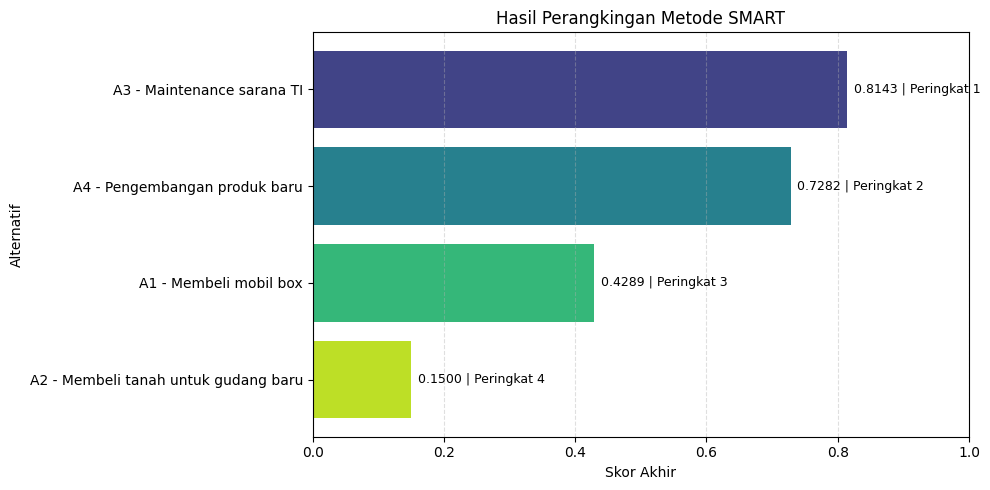

In [11]:
# ================================================================
# TAHAP 11 : VISUALISASI GRAFIK
# Tujuan  : Menampilkan hasil ranking dalam diagram batang.
# ================================================================

def visualisasi_ranking(
    hasil_ranking,
    kolom_alternatif
):
    """
    Membuat grafik hasil ranking yang menyesuaikan jumlah alternatif.
    """

    tampilkan_judul("VISUALISASI HASIL PERANGKINGAN")

    jumlah_alternatif = len(hasil_ranking)

    # Tinggi grafik menyesuaikan jumlah alternatif
    tinggi_grafik = max(5, jumlah_alternatif * 0.55)

    # Diagram batang horizontal agar nama panjang tetap terbaca
    plt.figure(figsize=(10, tinggi_grafik))

    warna = plt.cm.viridis(
        np.linspace(0.2, 0.9, jumlah_alternatif)
    )

    # Posisi batang memakai angka 0,1,2,... lalu nama dipasang
    # sebagai label, sehingga nama yang sama tidak menumpuk
    posisi_y = np.arange(jumlah_alternatif)

    batang = plt.barh(
        posisi_y,
        hasil_ranking["Skor Akhir"],
        color=warna
    )

    plt.yticks(
        posisi_y,
        hasil_ranking[kolom_alternatif].astype(str)
    )

    plt.xlabel("Skor Akhir")
    plt.ylabel("Alternatif")
    plt.title("Hasil Perangkingan Metode SMART")

    # Peringkat terbaik ditempatkan paling atas
    plt.gca().invert_yaxis()

    skor_maksimum = hasil_ranking["Skor Akhir"].max()

    # Batas sumbu agar label nilai tidak terpotong
    batas_kanan = max(1.0, skor_maksimum * 1.15)
    plt.xlim(0, batas_kanan)

    # Menulis skor dan peringkat di ujung setiap batang
    for batang_item, skor, peringkat in zip(
        batang,
        hasil_ranking["Skor Akhir"],
        hasil_ranking["Peringkat"]
    ):
        plt.text(
            skor + batas_kanan * 0.01,
            batang_item.get_y() + batang_item.get_height() / 2,
            f"{skor:.4f} | Peringkat {peringkat}",
            va="center",
            fontsize=9
        )

    plt.grid(axis="x", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

# --- JALANKAN: tampilkan grafik ---
visualisasi_ranking(
    hasil_ranking,
    kolom_alternatif
)

In [ ]:
# ================================================================
# TAHAP 12 : MENYIMPAN HASIL KE EXCEL
# Tujuan  : Menyimpan semua tahapan perhitungan ke satu file
#           Excel, masing-masing di sheet terpisah.
# ================================================================

def simpan_hasil_excel(
    data_awal,
    konfigurasi,
    statistik_kriteria,
    utility,
    nilai_terbobot,
    hasil_ranking
):
    """
    Menyimpan seluruh tahapan perhitungan ke dalam satu file Excel.
    """

    nama_file_hasil = "hasil_perhitungan_smart.xlsx"

    with pd.ExcelWriter(
        nama_file_hasil,
        engine="openpyxl"
    ) as writer:

        # --- 12.a. Menulis setiap tabel ke sheet masing-masing ---
        data_awal.to_excel(
            writer,
            sheet_name="Data Awal",
            index=False
        )

        konfigurasi.to_excel(
            writer,
            sheet_name="Konfigurasi",
            index=False
        )

        statistik_kriteria.to_excel(
            writer,
            sheet_name="Min Max",
            index=False
        )

        utility.to_excel(
            writer,
            sheet_name="Nilai Utility",
            index=False
        )

        nilai_terbobot.to_excel(
            writer,
            sheet_name="Nilai Terbobot",
            index=False
        )

        hasil_ranking.to_excel(
            writer,
            sheet_name="Hasil Ranking",
            index=False
        )

        # --- 12.b. Merapikan tampilan ---
        workbook = writer.book

        for nama_sheet in workbook.sheetnames:

            worksheet = workbook[nama_sheet]

            # Lebar kolom otomatis (maksimal 40 karakter)
            for kolom_sel in worksheet.columns:

                panjang_maksimum = 0
                huruf_kolom = kolom_sel[0].column_letter

                for sel in kolom_sel:

                    if sel.value is not None:
                        panjang = len(str(sel.value))
                        panjang_maksimum = max(
                            panjang_maksimum,
                            panjang
                        )

                worksheet.column_dimensions[
                    huruf_kolom
                ].width = min(panjang_maksimum + 2, 40)

            # Membekukan baris judul agar tetap terlihat saat scroll
            worksheet.freeze_panes = "A2"

    print(f"\nFile hasil berhasil dibuat: {nama_file_hasil}")

    return nama_file_hasil

# --- JALANKAN: simpan hasil ke Excel dan unduh ---
tampilkan_judul("PENYIMPANAN HASIL")

file_hasil = simpan_hasil_excel(
    data_awal=df,
    konfigurasi=konfigurasi,
    statistik_kriteria=statistik_kriteria,
    utility=nilai_utility,
    nilai_terbobot=nilai_terbobot,
    hasil_ranking=hasil_ranking
)

pilihan_download = input(
    "\nUnduh file hasil sekarang? [y/n]: "
).strip().lower()

if pilihan_download in ["y", "ya", "yes"]:
    files.download(file_hasil)
else:
    print(
        f"File '{file_hasil}' tetap tersimpan "
        "di penyimpanan sementara Google Colab."
    )

tampilkan_judul("PROGRAM SELESAI")
print("Perhitungan SMART berhasil dilakukan.")